In [1]:
from pathlib import Path
import copy
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla V100-SXM2-16GB


In [2]:
PROJECT_ROOT = Path(
    "/home/dutai/khacbinh/badminton-stroke"
)

JOINTS_ROOT = (
    PROJECT_ROOT
    / "processed"
    / "joints_npy_yolo26s_pose"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "processed"
    / "stgcn_v2"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# Dữ liệu
TARGET_FRAMES = 64
CONFIDENCE_THRESHOLD = 0.20

# DataLoader
BATCH_SIZE = 64
NUM_WORKERS = 4

# Training
NUM_EPOCHS = 100
WARMUP_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 12

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-3
LABEL_SMOOTHING = 0.05

# Augmentation
HORIZONTAL_FLIP_PROBABILITY = 0.5
JOINT_NOISE_SIGMA = 0.01
FRAME_DROP_PROBABILITY = 0.05


assert JOINTS_ROOT.exists(), (
    f"Không tìm thấy: {JOINTS_ROOT}"
)

print("Joints root:", JOINTS_ROOT)
print("Output root:", OUTPUT_ROOT)

Joints root: /home/dutai/khacbinh/badminton-stroke/processed/joints_npy_yolo26s_pose
Output root: /home/dutai/khacbinh/badminton-stroke/processed/stgcn_v2


In [ ]:
EXPERIMENTS = {
    "joint_baseline": {
        "bone": False,
        "hitter_only": False,
        "position": False,
        "shuttle": False,
    },

    "joint_bone": {
        "bone": True,
        "hitter_only": False,
        "position": False,
        "shuttle": False,
    },

    "joint_hitter": {
        "bone": False,
        "hitter_only": True,
        "position": False,
        "shuttle": False,
    },

    "joint_position": {
        "bone": False,
        "hitter_only": False,
        "position": True,
        "shuttle": False,
    },

    "joint_shuttle": {
        "bone": False,
        "hitter_only": False,
        "position": False,
        "shuttle": True,
    },

    "joint_bone_position_shuttle": {
        "bone": True,
        "hitter_only": False,
        "position": True,
        "shuttle": True,
    },
}


# Đổi tên này để chạy từng thí nghiệm.
EXPERIMENT_NAME = "joint_bone"

EXPERIMENT_CONFIG = EXPERIMENTS[
    EXPERIMENT_NAME
]

ABLATION_ROOT = (
    PROJECT_ROOT
    / "processed"
    / "stgcn_ablation"
    / EXPERIMENT_NAME
)

ABLATION_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

SHUTTLE_ROOT = (
    PROJECT_ROOT
    / "processed"
    / "shuttle_npy"
)

# Video của bạn hiện có kích thước này.
FRAME_WIDTH = 1280
FRAME_HEIGHT = 720

print("Experiment:", EXPERIMENT_NAME)
print(EXPERIMENT_CONFIG)
print("Output:", ABLATION_ROOT)

In [ ]:
MANIFEST_ROOT = (
    PROJECT_ROOT
    / "processed"
    / "manifests"
)


def find_score_path(joint_path):
    candidates = [
        joint_path.with_name(
            joint_path.name.replace(
                "_joints.npy",
                "_scores.npy",
            )
        ),
        joint_path.with_name(
            joint_path.name.replace(
                "joints.npy",
                "scores.npy",
            )
        ),
    ]

    for candidate in candidates:
        if (
            candidate.exists()
            and candidate != joint_path
        ):
            return candidate

    return None


def build_index(split):
    split_root = JOINTS_ROOT / split

    manifest_path = (
        MANIFEST_ROOT
        / f"{split}.csv"
    )

    assert split_root.exists(), split_root
    assert manifest_path.exists(), manifest_path

    manifest_df = pd.read_csv(
        manifest_path
    )

    manifest_columns = [
        "clip_id",
        "player",
        "video_path",
        "class_name",
    ]

    manifest_df = manifest_df[
        manifest_columns
    ].copy()

    records = []

    joint_files = sorted(
        split_root.rglob("*_joints.npy")
    )

    for joint_path in joint_files:
        relative_path = (
            joint_path.relative_to(
                split_root
            )
        )

        label_name = relative_path.parts[0]

        clip_id = joint_path.name.removesuffix(
            "_joints.npy"
        )

        score_path = find_score_path(
            joint_path
        )

        shuttle_path = (
            SHUTTLE_ROOT
            / split
            / label_name
            / f"{clip_id}_shuttle.npy"
        )

        records.append(
            {
                "clip_id": clip_id,
                "split": split,
                "label_name": label_name,
                "joint_path": str(joint_path),
                "score_path": (
                    str(score_path)
                    if score_path is not None
                    else ""
                ),
                "shuttle_path": str(
                    shuttle_path
                ),
            }
        )

    index_df = pd.DataFrame(records)

    index_df = index_df.merge(
        manifest_df,
        on="clip_id",
        how="left",
        suffixes=("", "_manifest"),
        validate="one_to_one",
    )

    assert index_df["player"].notna().all(), (
        f"Có clip trong {split} không ghép "
        "được với manifest"
    )

    return index_df


train_df = build_index("train")
val_df = build_index("val")
test_df = build_index("test")

class_names = sorted(
    train_df["label_name"]
    .unique()
    .tolist()
)

class_to_id = {
    name: index
    for index, name
    in enumerate(class_names)
}

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

display(
    train_df[
        [
            "clip_id",
            "label_name",
            "player",
            "joint_path",
        ]
    ].head()
)

Số lớp: 18
Train: 5462
Validation: 1176
Test: 1180
Các lớp:
0 00_Short Serve
1 01_Cross Court Flight
2 02_Lift
3 03_Tap Smash
4 04_Block
5 05_Drop Shot
6 06_Push Shot
7 07_Transitional Slice
8 08_Cut
9 09_Rush Shot
10 10_Defensive Clear
11 11_Defensive Drive
12 12_Clear
13 13_Long Serve
14 14_Smash
15 15_Flat Shot
16 16_Rear Court Flat Drive
17 17_Short Flat Shot


,split,label_name,joint_path,score_path
0,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,
1,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,
2,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,
3,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,
4,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,


In [4]:
all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
)

audit_records = []

for row in tqdm(
    all_df.itertuples(index=False),
    total=len(all_df),
    desc="Audit dữ liệu",
):
    try:
        joints = np.load(
            row.joint_path,
            mmap_mode="r",
        )

        valid_shape = (
            joints.ndim == 4
            and joints.shape[1:] == (2, 17, 2)
        )

        audit_records.append(
            {
                "split": row.split,
                "label_name": row.label_name,
                "num_frames": (
                    joints.shape[0]
                    if joints.ndim > 0
                    else 0
                ),
                "shape": tuple(joints.shape),
                "valid": valid_shape,
                "joint_path": row.joint_path,
                "error": "",
            }
        )

    except Exception as error:
        audit_records.append(
            {
                "split": row.split,
                "label_name": row.label_name,
                "num_frames": 0,
                "shape": None,
                "valid": False,
                "joint_path": row.joint_path,
                "error": (
                    f"{type(error).__name__}: "
                    f"{error}"
                ),
            }
        )

audit_df = pd.DataFrame(audit_records)

print(
    "File hợp lệ:",
    int(audit_df["valid"].sum()),
    "/",
    len(audit_df),
)

display(
    audit_df.loc[
        audit_df["valid"],
        "num_frames",
    ].describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

invalid_df = audit_df[
    ~audit_df["valid"]
]

if len(invalid_df):
    display(invalid_df.head(20))

Audit dữ liệu: 100%|██████████| 7818/7818 [00:01<00:00, 5286.19it/s]

File hợp lệ: 7818 / 7818


count    7818.000000
mean       33.067920
std        12.479478
min         1.000000
50%        31.000000
75%        41.000000
90%        51.000000
95%        56.000000
99%        65.000000
max       104.000000
Name: num_frames, dtype: float64

split,test,train,val
label_name,,,
00_Short Serve,132,619,129
01_Cross Court Flight,35,111,20
02_Lift,127,529,102
03_Tap Smash,21,73,15
04_Block,59,214,42
05_Drop Shot,122,560,130
06_Push Shot,51,300,50
07_Transitional Slice,18,79,26
08_Cut,101,406,78


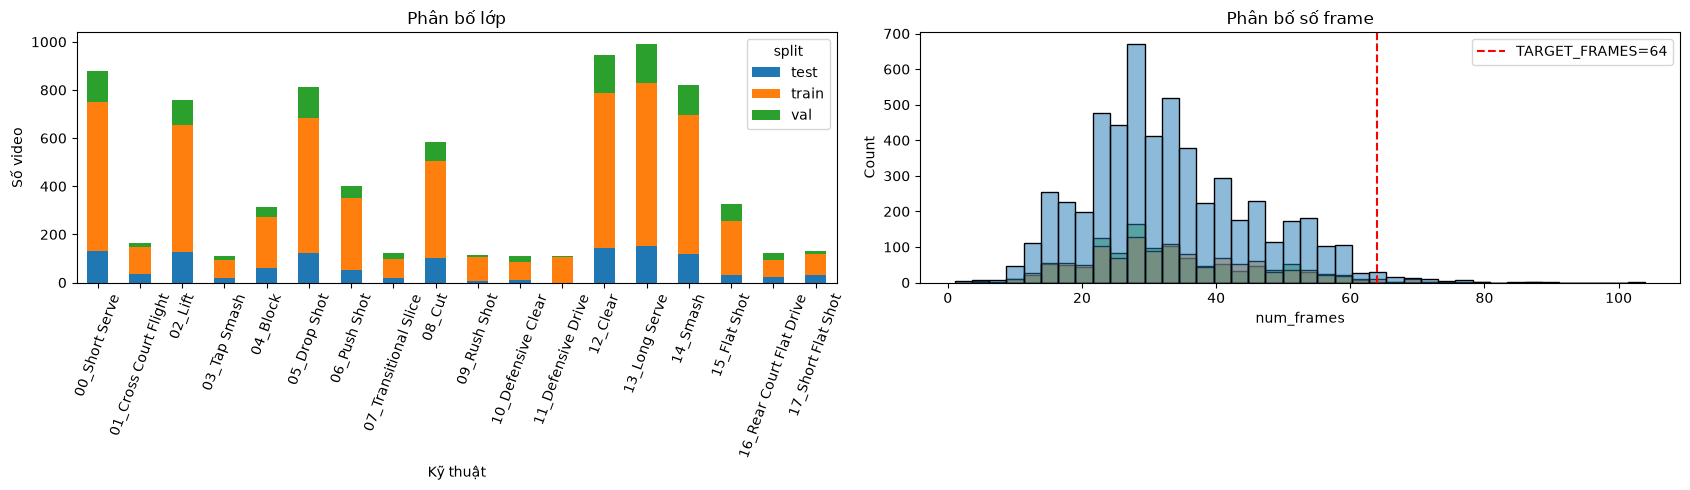

In [5]:
class_distribution = (
    all_df
    .groupby(["label_name", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(class_names)
)

display(class_distribution)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 5),
)

class_distribution.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
)

axes[0].set_title("Phân bố lớp")
axes[0].set_xlabel("Kỹ thuật")
axes[0].set_ylabel("Số video")
axes[0].tick_params(
    axis="x",
    rotation=70,
)

sns.histplot(
    data=audit_df[audit_df["valid"]],
    x="num_frames",
    hue="split",
    bins=40,
    ax=axes[1],
)

axes[1].axvline(
    TARGET_FRAMES,
    color="red",
    linestyle="--",
    label=f"TARGET_FRAMES={TARGET_FRAMES}",
)

axes[1].set_title("Phân bố số frame")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
LEFT_SHOULDER = 5
RIGHT_SHOULDER = 6
LEFT_HIP = 11
RIGHT_HIP = 12

COCO_LEFT_RIGHT_PAIRS = [
    (1, 2),
    (3, 4),
    (5, 6),
    (7, 8),
    (9, 10),
    (11, 12),
    (13, 14),
    (15, 16),
]


def load_scores(score_path, joints):
    if score_path:
        scores = np.load(
            score_path
        ).astype(np.float32)

        if scores.shape == joints.shape[:-1]:
            return scores

    # Fallback nếu không có score file.
    return np.any(
        joints != 0,
        axis=-1,
    ).astype(np.float32)


def normalize_skeleton(
    joints,
    scores,
    confidence_threshold,
):
    joints = joints.astype(
        np.float32,
        copy=True,
    )

    scores = scores.astype(
        np.float32,
        copy=True,
    )

    valid = (
        scores >= confidence_threshold
    )

    num_frames, num_people, _, _ = (
        joints.shape
    )

    normalized = np.zeros_like(
        joints,
        dtype=np.float32,
    )

    for person_index in range(num_people):
        person_xy = joints[
            :, person_index
        ]

        person_valid = valid[
            :, person_index
        ]

        centers = np.zeros(
            (num_frames, 2),
            dtype=np.float32,
        )

        torso_lengths = []

        for frame_index in range(num_frames):
            hip_valid = person_valid[
                frame_index,
                [LEFT_HIP, RIGHT_HIP],
            ]

            if hip_valid.all():
                centers[frame_index] = (
                    person_xy[
                        frame_index,
                        [LEFT_HIP, RIGHT_HIP],
                    ].mean(axis=0)
                )

            elif person_valid[
                frame_index
            ].any():
                centers[frame_index] = (
                    person_xy[
                        frame_index,
                        person_valid[frame_index],
                    ].mean(axis=0)
                )

            torso_valid = person_valid[
                frame_index,
                [
                    LEFT_SHOULDER,
                    RIGHT_SHOULDER,
                    LEFT_HIP,
                    RIGHT_HIP,
                ],
            ]

            if torso_valid.all():
                shoulder_center = person_xy[
                    frame_index,
                    [
                        LEFT_SHOULDER,
                        RIGHT_SHOULDER,
                    ],
                ].mean(axis=0)

                hip_center = person_xy[
                    frame_index,
                    [
                        LEFT_HIP,
                        RIGHT_HIP,
                    ],
                ].mean(axis=0)

                torso_lengths.append(
                    np.linalg.norm(
                        shoulder_center
                        - hip_center
                    )
                )

        centered = (
            person_xy
            - centers[:, None, :]
        )

        if torso_lengths:
            scale = float(
                np.median(torso_lengths)
            )

        else:
            visible_points = centered[
                person_valid
            ]

            if len(visible_points):
                scale = float(
                    np.max(
                        np.ptp(
                            visible_points,
                            axis=0,
                        )
                    )
                )
            else:
                scale = 1.0

        scale = max(scale, 1e-6)

        centered /= scale
        centered[~person_valid] = 0.0

        normalized[:, person_index] = (
            centered
        )

    scores[~valid] = 0.0

    return normalized, scores

In [7]:
def crop_or_pad(
    joints,
    scores,
    target_frames,
    training,
):
    """
    Giữ nguyên frame rate.

    Video dài:
        random crop khi train,
        center crop khi val/test.

    Video ngắn:
        padding về target_frames.
    """

    num_frames = len(joints)

    if num_frames >= target_frames:
        max_start = (
            num_frames - target_frames
        )

        if training and max_start > 0:
            start = random.randint(
                0,
                max_start,
            )
        else:
            start = max_start // 2

        end = start + target_frames

        return (
            joints[start:end],
            scores[start:end],
        )

    output_joints = np.zeros(
        (
            target_frames,
            *joints.shape[1:],
        ),
        dtype=np.float32,
    )

    output_scores = np.zeros(
        (
            target_frames,
            *scores.shape[1:],
        ),
        dtype=np.float32,
    )

    empty_frames = (
        target_frames - num_frames
    )

    if training and empty_frames > 0:
        start = random.randint(
            0,
            empty_frames,
        )
    else:
        start = empty_frames // 2

    end = start + num_frames

    output_joints[start:end] = joints
    output_scores[start:end] = scores

    return output_joints, output_scores


def horizontal_flip(joints, scores):
    joints = joints.copy()
    scores = scores.copy()

    # Đảo trục x.
    joints[..., 0] *= -1

    # Đổi joint trái/phải.
    for left, right in (
        COCO_LEFT_RIGHT_PAIRS
    ):
        left_joint = joints[
            :, :, left
        ].copy()

        joints[:, :, left] = (
            joints[:, :, right]
        )

        joints[:, :, right] = (
            left_joint
        )

        left_score = scores[
            :, :, left
        ].copy()

        scores[:, :, left] = (
            scores[:, :, right]
        )

        scores[:, :, right] = (
            left_score
        )

    return joints, scores


def add_joint_noise(
    joints,
    scores,
    sigma,
):
    joints = joints.copy()

    visible = scores > 0

    noise = np.random.normal(
        loc=0.0,
        scale=sigma,
        size=joints.shape,
    ).astype(np.float32)

    joints[visible] += noise[visible]

    return joints


def random_drop_frames(
    joints,
    scores,
    probability,
):
    joints = joints.copy()
    scores = scores.copy()

    for frame_index in range(
        1,
        len(joints),
    ):
        has_pose = np.any(
            scores[frame_index] > 0
        )

        if (
            has_pose
            and random.random() < probability
        ):
            joints[frame_index] = (
                joints[frame_index - 1]
            )

            scores[frame_index] = (
                scores[frame_index - 1]
            )

    return joints, scores


def create_motion(
    joints,
    scores,
):
    motion = np.zeros_like(
        joints,
        dtype=np.float32,
    )

    valid_pair = (
        (scores[1:] > 0)
        & (scores[:-1] > 0)
    )

    difference = (
        joints[1:]
        - joints[:-1]
    )

    motion[1:] = np.where(
        valid_pair[..., None],
        difference,
        0.0,
    )

    return motion

In [ ]:
COCO_BONES = [
    (0, 1),
    (0, 2),
    (1, 3),
    (2, 4),
    (5, 6),
    (5, 7),
    (7, 9),
    (6, 8),
    (8, 10),
    (5, 11),
    (6, 12),
    (11, 12),
    (11, 13),
    (13, 15),
    (12, 14),
    (14, 16),
]

ARM_JOINTS = [
    5, 6,       # Shoulder
    7, 8,       # Elbow
    9, 10,      # Wrist
]

LEFT_ANKLE = 15
RIGHT_ANKLE = 16


def create_bone_features(
    joints,
    scores,
):
    """
    joints: (T, M, 17, 2)
    scores: (T, M, 17)

    Bone được đặt tại joint con để vẫn giữ
    graph COCO gồm 17 node.
    """

    bones = np.zeros_like(
        joints,
        dtype=np.float32,
    )

    bone_scores = np.zeros_like(
        scores,
        dtype=np.float32,
    )

    for parent, child in COCO_BONES:
        valid = (
            (scores[:, :, parent] > 0)
            & (scores[:, :, child] > 0)
        )

        vector = (
            joints[:, :, child]
            - joints[:, :, parent]
        )

        bones[:, :, child] = np.where(
            valid[..., None],
            vector,
            0.0,
        )

        bone_scores[:, :, child] = np.where(
            valid,
            np.minimum(
                scores[:, :, parent],
                scores[:, :, child],
            ),
            0.0,
        )

    bone_motion = create_motion(
        bones,
        bone_scores,
    )

    # bx, by, dbx, dby
    return np.concatenate(
        [
            bones,
            bone_motion,
        ],
        axis=-1,
    )


def extract_player_positions(
    raw_joints,
    raw_scores,
    frame_width,
    frame_height,
    confidence_threshold,
):
    """
    Kết quả: (T, M, 3)
    [position_x, position_y, valid]

    Tọa độ được đưa về gần [-0.5, 0.5].
    Đây mới là tọa độ ảnh, chưa phải court
    homography như bài BST.
    """

    num_frames, num_people = (
        raw_joints.shape[:2]
    )

    positions = np.zeros(
        (num_frames, num_people, 3),
        dtype=np.float32,
    )

    for frame_index in range(num_frames):
        for person_index in range(
            num_people
        ):
            ankle_valid = (
                raw_scores[
                    frame_index,
                    person_index,
                    [LEFT_ANKLE, RIGHT_ANKLE],
                ]
                >= confidence_threshold
            )

            if ankle_valid.all():
                point = raw_joints[
                    frame_index,
                    person_index,
                    [LEFT_ANKLE, RIGHT_ANKLE],
                ].mean(axis=0)

            else:
                # Fallback bằng tâm hai hông.
                hip_valid = (
                    raw_scores[
                        frame_index,
                        person_index,
                        [LEFT_HIP, RIGHT_HIP],
                    ]
                    >= confidence_threshold
                )

                if not hip_valid.all():
                    continue

                point = raw_joints[
                    frame_index,
                    person_index,
                    [LEFT_HIP, RIGHT_HIP],
                ].mean(axis=0)

            positions[
                frame_index,
                person_index,
                0,
            ] = (
                point[0] / frame_width
                - 0.5
            )

            positions[
                frame_index,
                person_index,
                1,
            ] = (
                point[1] / frame_height
                - 0.5
            )

            positions[
                frame_index,
                person_index,
                2,
            ] = 1.0

    return positions


def select_hitter_by_motion(
    joints,
    scores,
):
    """
    Hitter proxy:
    chọn người có chuyển động tay lớn nhất.

    Đây là heuristic để thử nghiệm, chưa phải
    nhãn hitter chính xác.
    """

    motion = create_motion(
        joints,
        scores,
    )

    valid = (
        scores[:, :, ARM_JOINTS] > 0
    )

    arm_motion = motion[
        :, :, ARM_JOINTS
    ]

    energy = np.linalg.norm(
        arm_motion,
        axis=-1,
    )

    energy = (
        energy * valid
    ).sum(axis=(0, 2))

    if np.allclose(energy, 0):
        visibility = (
            scores > 0
        ).sum(axis=(0, 2))

        return int(
            np.argmax(visibility)
        )

    return int(np.argmax(energy))

In [ ]:
def crop_or_pad_aligned(
    arrays,
    target_frames,
    training,
):
    """
    Tất cả array phải có chiều đầu tiên là T.
    """

    num_frames = len(arrays[0])

    assert all(
        len(array) == num_frames
        for array in arrays
    )

    if num_frames >= target_frames:
        max_start = (
            num_frames - target_frames
        )

        if training and max_start > 0:
            start = random.randint(
                0,
                max_start,
            )
        else:
            start = max_start // 2

        end = start + target_frames

        return tuple(
            array[start:end]
            for array in arrays
        )

    empty_frames = (
        target_frames - num_frames
    )

    if training and empty_frames > 0:
        start = random.randint(
            0,
            empty_frames,
        )
    else:
        start = empty_frames // 2

    end = start + num_frames

    outputs = []

    for array in arrays:
        output = np.zeros(
            (
                target_frames,
                *array.shape[1:],
            ),
            dtype=array.dtype,
        )

        output[start:end] = array
        outputs.append(output)

    return tuple(outputs)


def random_drop_aligned(
    arrays,
    scores,
    probability,
):
    arrays = [
        array.copy()
        for array in arrays
    ]

    scores = scores.copy()

    for frame_index in range(
        1,
        len(scores),
    ):
        has_pose = np.any(
            scores[frame_index] > 0
        )

        if (
            has_pose
            and random.random()
            < probability
        ):
            for array in arrays:
                array[frame_index] = (
                    array[frame_index - 1]
                )

            scores[frame_index] = (
                scores[frame_index - 1]
            )

    return arrays, scores

In [ ]:
def tracknet_csv_to_npy(
    csv_path,
    output_path,
    frame_count,
    frame_width=1280,
    frame_height=720,
):
    frame = pd.read_csv(csv_path)

    column_map = {
        column.lower(): column
        for column in frame.columns
    }

    frame_column = column_map.get(
        "frame",
        column_map.get("frame_id"),
    )

    x_column = column_map.get(
        "x",
        column_map.get("x-coordinate"),
    )

    y_column = column_map.get(
        "y",
        column_map.get("y-coordinate"),
    )

    visibility_column = column_map.get(
        "visibility",
        column_map.get("confidence"),
    )

    if x_column is None or y_column is None:
        raise ValueError(
            f"Không tìm thấy cột X/Y: "
            f"{frame.columns.tolist()}"
        )

    shuttle = np.zeros(
        (frame_count, 3),
        dtype=np.float32,
    )

    for row_index, row in (
        frame.iterrows()
    ):
        frame_index = (
            int(row[frame_column])
            if frame_column is not None
            else row_index
        )

        if not (
            0 <= frame_index < frame_count
        ):
            continue

        x = float(row[x_column])
        y = float(row[y_column])

        confidence = (
            float(row[visibility_column])
            if visibility_column is not None
            else 1.0
        )

        if (
            confidence <= 0
            or x <= 0
            or y <= 0
        ):
            continue

        shuttle[frame_index, 0] = (
            x / frame_width - 0.5
        )

        shuttle[frame_index, 1] = (
            y / frame_height - 0.5
        )

        shuttle[frame_index, 2] = (
            confidence
        )

    output_path = Path(output_path)

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    np.save(
        output_path,
        shuttle,
    )

In [ ]:
class BadmintonAblationDataset(Dataset):
    def __init__(
        self,
        index_df,
        class_to_id,
        experiment_config,
        target_frames=64,
        confidence_threshold=0.2,
        training=False,
    ):
        self.index_df = (
            index_df
            .reset_index(drop=True)
            .copy()
        )

        self.class_to_id = class_to_id
        self.config = experiment_config

        self.target_frames = (
            target_frames
        )

        self.confidence_threshold = (
            confidence_threshold
        )

        self.training = training

    def __len__(self):
        return len(self.index_df)

    def _load_shuttle(
        self,
        row,
        num_frames,
    ):
        if not self.config["shuttle"]:
            return np.zeros(
                (num_frames, 3),
                dtype=np.float32,
            )

        shuttle_path = Path(
            row["shuttle_path"]
        )

        if not shuttle_path.exists():
            raise FileNotFoundError(
                f"Thiếu shuttle file: "
                f"{shuttle_path}"
            )

        shuttle = np.load(
            shuttle_path
        ).astype(np.float32)

        if shuttle.shape != (
            num_frames,
            3,
        ):
            raise ValueError(
                f"Shuttle shape sai: "
                f"{shuttle.shape}, "
                f"mong đợi {(num_frames, 3)}"
            )

        return shuttle

    def __getitem__(self, index):
        row = self.index_df.iloc[index]

        raw_joints = np.load(
            row["joint_path"]
        ).astype(np.float32)

        if (
            raw_joints.ndim != 4
            or raw_joints.shape[1:]
            != (2, 17, 2)
        ):
            raise ValueError(
                f"Joint shape sai: "
                f"{raw_joints.shape}"
            )

        raw_scores = load_scores(
            row["score_path"],
            raw_joints,
        )

        positions = (
            extract_player_positions(
                raw_joints,
                raw_scores,
                FRAME_WIDTH,
                FRAME_HEIGHT,
                self.confidence_threshold,
            )
        )

        shuttle = self._load_shuttle(
            row,
            len(raw_joints),
        )

        joints, scores = normalize_skeleton(
            raw_joints,
            raw_scores,
            self.confidence_threshold,
        )

        (
            joints,
            scores,
            positions,
            shuttle,
        ) = crop_or_pad_aligned(
            [
                joints,
                scores,
                positions,
                shuttle,
            ],
            self.target_frames,
            self.training,
        )

        if self.training:
            if (
                random.random()
                < HORIZONTAL_FLIP_PROBABILITY
            ):
                joints, scores = (
                    horizontal_flip(
                        joints,
                        scores,
                    )
                )

                # Position đã centered.
                positions[..., 0] *= -1

                if self.config["shuttle"]:
                    shuttle[..., 0] *= -1

            if JOINT_NOISE_SIGMA > 0:
                joints = add_joint_noise(
                    joints,
                    scores,
                    JOINT_NOISE_SIGMA,
                )

            if FRAME_DROP_PROBABILITY > 0:
                aligned, scores = (
                    random_drop_aligned(
                        [
                            joints,
                            positions,
                            shuttle,
                        ],
                        scores,
                        FRAME_DROP_PROBABILITY,
                    )
                )

                (
                    joints,
                    positions,
                    shuttle,
                ) = aligned

        joint_motion = create_motion(
            joints,
            scores,
        )

        feature_parts = [
            # x, y
            joints,

            # confidence
            scores[..., None],

            # dx, dy
            joint_motion,
        ]

        if self.config["bone"]:
            bone_features = (
                create_bone_features(
                    joints,
                    scores,
                )
            )

            feature_parts.append(
                bone_features
            )

        if self.config["position"]:
            # (T, M, 3)
            # -> (T, M, 17, 3)
            position_features = np.repeat(
                positions[:, :, None, :],
                repeats=17,
                axis=2,
            )

            feature_parts.append(
                position_features
            )

        if self.config["shuttle"]:
            shuttle_xy = shuttle[:, :2]
            shuttle_confidence = shuttle[:, 2]

            shuttle_motion = np.zeros_like(
                shuttle_xy,
                dtype=np.float32,
            )

            valid_pair = (
                (shuttle_confidence[1:] > 0)
                & (shuttle_confidence[:-1] > 0)
            )

            shuttle_motion[1:] = np.where(
                valid_pair[:, None],
                (
                    shuttle_xy[1:]
                    - shuttle_xy[:-1]
                ),
                0.0,
            )

            shuttle_features = np.concatenate(
                [
                    shuttle_xy,
                    shuttle_confidence[
                        :, None
                    ],
                    shuttle_motion,
                ],
                axis=-1,
            )
            # (T, 5)

            shuttle_features = (
                shuttle_features[
                    :, None, None, :
                ]
            )

            shuttle_features = np.repeat(
                shuttle_features,
                repeats=2,
                axis=1,
            )

            shuttle_features = np.repeat(
                shuttle_features,
                repeats=17,
                axis=2,
            )

            feature_parts.append(
                shuttle_features
            )

        features = np.concatenate(
            feature_parts,
            axis=-1,
        )
        # (T, M, V, C)

        if self.config["hitter_only"]:
            hitter_index = (
                select_hitter_by_motion(
                    joints,
                    scores,
                )
            )

            # Chỉ còn một person.
            features = features[
                :,
                hitter_index:
                hitter_index + 1,
            ]

        # (T, M, V, C)
        # -> (C, T, V, M)
        features = features.transpose(
            3,
            0,
            2,
            1,
        )

        label = self.class_to_id[
            row["label_name"]
        ]

        return (
            torch.from_numpy(
                features.astype(np.float32)
            ),
            torch.tensor(
                label,
                dtype=torch.long,
            ),
        )

In [ ]:
train_dataset = BadmintonAblationDataset(
    train_df,
    class_to_id,
    EXPERIMENT_CONFIG,
    target_frames=TARGET_FRAMES,
    training=True,
)

val_dataset = BadmintonAblationDataset(
    val_df,
    class_to_id,
    EXPERIMENT_CONFIG,
    target_frames=TARGET_FRAMES,
    training=False,
)

test_dataset = BadmintonAblationDataset(
    test_df,
    class_to_id,
    EXPERIMENT_CONFIG,
    target_frames=TARGET_FRAMES,
    training=False,
)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": (
        DEVICE.type == "cuda"
    ),
    "persistent_workers": (
        NUM_WORKERS > 0
    ),
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    **loader_options,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_options,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_options,
)

features_batch, labels_batch = next(
    iter(train_loader)
)

INPUT_CHANNELS = (
    features_batch.shape[1]
)

NUM_PERSONS = (
    features_batch.shape[-1]
)

print("Experiment:", EXPERIMENT_NAME)
print("Features:", features_batch.shape)
print("Input channels:", INPUT_CHANNELS)
print("Persons:", NUM_PERSONS)
print(
    "Finite:",
    torch.isfinite(
        features_batch
    ).all().item(),
)

Features: torch.Size([64, 5, 64, 17, 2])
Labels: torch.Size([64])
Finite: tensor(True)


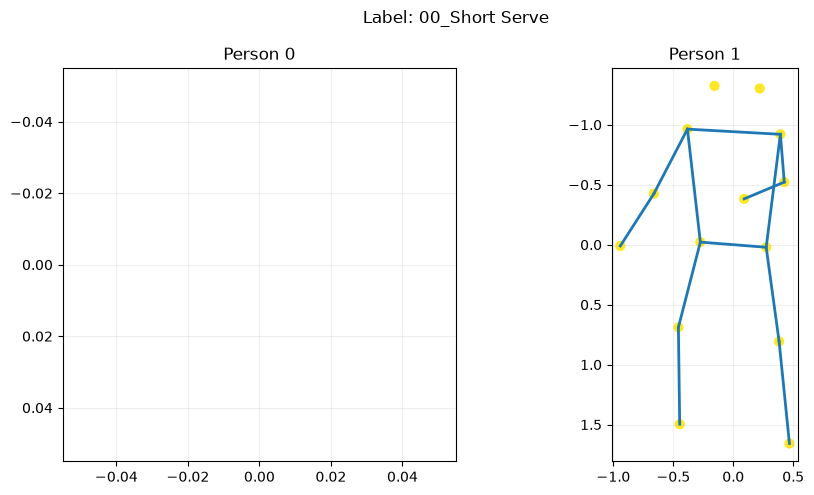

In [10]:
COCO_EDGES = [
    (0, 1),
    (0, 2),
    (1, 3),
    (2, 4),
    (5, 6),
    (5, 7),
    (7, 9),
    (6, 8),
    (8, 10),
    (5, 11),
    (6, 12),
    (11, 12),
    (11, 13),
    (13, 15),
    (12, 14),
    (14, 16),
]


def show_skeleton(
    dataset,
    sample_index=0,
    frame_index=None,
):
    features, label = dataset[
        sample_index
    ]

    features = features.numpy()

    if frame_index is None:
        frame_index = (
            features.shape[1] // 2
        )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(10, 5),
    )

    for person_index, axis in enumerate(
        axes
    ):
        xy = features[
            :2,
            frame_index,
            :,
            person_index,
        ].T

        confidence = features[
            2,
            frame_index,
            :,
            person_index,
        ]

        for start, end in COCO_EDGES:
            if (
                confidence[start] > 0
                and confidence[end] > 0
            ):
                axis.plot(
                    [
                        xy[start, 0],
                        xy[end, 0],
                    ],
                    [
                        xy[start, 1],
                        xy[end, 1],
                    ],
                    color="tab:blue",
                    linewidth=2,
                )

        visible = confidence > 0

        axis.scatter(
            xy[visible, 0],
            xy[visible, 1],
            c=confidence[visible],
            cmap="viridis",
            vmin=0,
            vmax=1,
            s=40,
        )

        axis.set_title(
            f"Person {person_index}"
        )

        axis.set_aspect("equal")
        axis.invert_yaxis()
        axis.grid(alpha=0.2)

    fig.suptitle(
        f"Label: {class_names[int(label)]}"
    )

    plt.tight_layout()
    plt.show()


show_skeleton(
    val_dataset,
    sample_index=0,
)

In [11]:
def normalize_digraph(matrix):
    degree = matrix.sum(axis=0)

    inverse_degree = np.zeros_like(
        degree,
        dtype=np.float32,
    )

    valid = degree > 0

    inverse_degree[valid] = (
        1.0 / degree[valid]
    )

    return (
        matrix
        @ np.diag(inverse_degree)
    )


def build_coco_adjacency():
    num_joints = 17

    identity = np.eye(
        num_joints,
        dtype=np.float32,
    )

    inward = np.zeros(
        (num_joints, num_joints),
        dtype=np.float32,
    )

    for source, target in COCO_EDGES:
        inward[target, source] = 1.0

    outward = inward.T

    adjacency = np.stack(
        [
            identity,
            normalize_digraph(inward),
            normalize_digraph(outward),
        ]
    )

    return torch.tensor(
        adjacency,
        dtype=torch.float32,
    )


ADJACENCY = build_coco_adjacency()

print("Adjacency:", ADJACENCY.shape)

Adjacency: torch.Size([3, 17, 17])


In [12]:
class SpatialGraphConv(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        spatial_kernel_size,
    ):
        super().__init__()

        self.spatial_kernel_size = (
            spatial_kernel_size
        )

        self.conv = nn.Conv2d(
            in_channels,
            out_channels
            * spatial_kernel_size,
            kernel_size=1,
        )

    def forward(
        self,
        x,
        adjacency,
    ):
        x = self.conv(x)

        n, kc, t, v = x.shape

        x = x.view(
            n,
            self.spatial_kernel_size,
            kc // self.spatial_kernel_size,
            t,
            v,
        )

        x = torch.einsum(
            "nkctv,kvw->nctw",
            x,
            adjacency,
        )

        return x.contiguous()

In [13]:
class STGCNBlock(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        spatial_kernel_size,
        stride=1,
        dropout=0.4,
        residual=True,
    ):
        super().__init__()

        self.gcn = SpatialGraphConv(
            in_channels,
            out_channels,
            spatial_kernel_size,
        )

        self.tcn = nn.Sequential(
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=(9, 1),
                stride=(stride, 1),
                padding=(4, 0),
            ),

            nn.BatchNorm2d(out_channels),
            nn.Dropout(dropout),
        )

        if not residual:
            self.residual = lambda x: 0

        elif (
            in_channels == out_channels
            and stride == 1
        ):
            self.residual = nn.Identity()

        else:
            self.residual = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=(stride, 1),
                ),
                nn.BatchNorm2d(
                    out_channels
                ),
            )

        self.relu = nn.ReLU(
            inplace=True
        )

    def forward(
        self,
        x,
        adjacency,
    ):
        residual = self.residual(x)

        x = self.gcn(
            x,
            adjacency,
        )

        x = self.tcn(x)
        x = x + residual

        return self.relu(x)

In [14]:
class STGCNV2(nn.Module):
    def __init__(
        self,
        in_channels,
        num_classes,
        adjacency,
        dropout=0.4,
    ):
        super().__init__()

        self.register_buffer(
            "adjacency",
            adjacency,
        )

        num_joints = adjacency.shape[-1]

        self.data_bn = nn.BatchNorm1d(
            in_channels * num_joints
        )

        configurations = [
            (in_channels, 32, 1, False),
            (32, 32, 1, True),
            (32, 64, 2, True),
            (64, 64, 1, True),
            (64, 128, 2, True),
            (128, 128, 1, True),
        ]

        self.blocks = nn.ModuleList(
            [
                STGCNBlock(
                    in_channels=in_c,
                    out_channels=out_c,
                    spatial_kernel_size=(
                        adjacency.shape[0]
                    ),
                    stride=stride,
                    dropout=dropout,
                    residual=residual,
                )
                for (
                    in_c,
                    out_c,
                    stride,
                    residual,
                ) in configurations
            ]
        )

        self.edge_importance = (
            nn.ParameterList(
                [
                    nn.Parameter(
                        torch.ones_like(
                            adjacency
                        )
                    )
                    for _ in self.blocks
                ]
            )
        )

        self.person_attention = nn.Sequential(
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(
                128,
                num_classes,
            ),
        )

    def forward(
        self,
        x,
        return_attention=False,
    ):
        # x: (N, C, T, V, M)
        n, c, t, v, m = x.shape

        x = x.permute(
            0, 4, 3, 1, 2
        ).contiguous()

        x = x.view(
            n * m,
            v * c,
            t,
        )

        x = self.data_bn(x)

        x = x.view(
            n,
            m,
            v,
            c,
            t,
        )

        x = x.permute(
            0, 1, 3, 4, 2
        ).contiguous()

        x = x.view(
            n * m,
            c,
            t,
            v,
        )

        for block, importance in zip(
            self.blocks,
            self.edge_importance,
        ):
            x = block(
                x,
                self.adjacency
                * importance,
            )

        x = F.adaptive_avg_pool2d(
            x,
            output_size=1,
        )

        x = x.view(
            n,
            m,
            128,
        )

        attention_logits = (
            self.person_attention(x)
            .squeeze(-1)
        )

        attention = torch.softmax(
            attention_logits,
            dim=1,
        )

        pooled = (
            x
            * attention.unsqueeze(-1)
        ).sum(dim=1)

        logits = self.classifier(
            pooled
        )

        if return_attention:
            return logits, attention

        return logits

In [ ]:
model = STGCNV2(
    in_channels=INPUT_CHANNELS,
    num_classes=len(class_names),
    adjacency=ADJACENCY,
    dropout=0.4,
).to(DEVICE)

with torch.no_grad():
    logits, attention = model(
        features_batch[:2].to(DEVICE),
        return_attention=True,
    )

print("Logits:", logits.shape)
print("Attention:", attention)
print(
    "Parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}",
)

Logits: torch.Size([2, 18])
Attention: tensor([[0.4573, 0.5427],
        [0.5001, 0.4999]], device='cuda:0')
Trainable parameters: 513,199


In [16]:
train_counts = (
    train_df["label_name"]
    .value_counts()
    .reindex(class_names)
    .to_numpy()
)

class_weights = (
    len(train_df)
    / (
        len(class_names)
        * train_counts
    )
)

# Không để lớp hiếm có trọng số quá lớn.
class_weights = np.clip(
    class_weights,
    0.5,
    3.0,
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

print("Class weights:")

display(
    pd.DataFrame(
        {
            "class": class_names,
            "train_count": train_counts,
            "weight": (
                class_weights.cpu().numpy()
            ),
        }
    )
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

warmup_scheduler = (
    torch.optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=0.2,
        end_factor=1.0,
        total_iters=WARMUP_EPOCHS,
    )
)

cosine_scheduler = (
    torch.optim.lr_scheduler
    .CosineAnnealingLR(
        optimizer,
        T_max=(
            NUM_EPOCHS
            - WARMUP_EPOCHS
        ),
        eta_min=1e-6,
    )
)

scheduler = (
    torch.optim.lr_scheduler
    .SequentialLR(
        optimizer,
        schedulers=[
            warmup_scheduler,
            cosine_scheduler,
        ],
        milestones=[
            WARMUP_EPOCHS,
        ],
    )
)

Class weights:


,class,train_count,weight
0,00_Short Serve,619,0.500000
1,01_Cross Court Flight,111,2.733734
2,02_Lift,529,0.573619
3,03_Tap Smash,73,3.000000
4,04_Block,214,1.417965
5,05_Drop Shot,560,0.541865
6,06_Push Shot,300,1.011482
7,07_Transitional Slice,79,3.000000
8,08_Cut,406,0.747400
9,09_Rush Shot,102,2.974946


In [17]:
def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
):
    training = optimizer is not None

    model.train(training)

    total_loss = 0.0
    y_true = []
    y_pred = []

    progress = tqdm(
        loader,
        leave=False,
        desc=(
            "Train"
            if training
            else "Validation"
        ),
    )

    for features, labels in progress:
        features = features.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )

        if training:
            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(
            training
        ):
            logits = model(features)

            loss = criterion(
                logits,
                labels,
            )

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=5.0,
                )

                optimizer.step()

        total_loss += (
            loss.item()
            * len(labels)
        )

        predictions = logits.argmax(
            dim=1
        )

        y_true.extend(
            labels
            .detach()
            .cpu()
            .tolist()
        )

        y_pred.extend(
            predictions
            .detach()
            .cpu()
            .tolist()
        )

    return {
        "loss": (
            total_loss
            / len(loader.dataset)
        ),
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    }

In [ ]:
CHECKPOINT_PATH = (
    ABLATION_ROOT
    / "best.pt"
)
history = []

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(
    1,
    NUM_EPOCHS + 1,
):
    started = time.time()

    train_metrics = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
    )

    val_metrics = run_epoch(
        model,
        val_loader,
        criterion,
    )

    scheduler.step()

    result = {
        "epoch": epoch,
        "train_loss": (
            train_metrics["loss"]
        ),
        "train_accuracy": (
            train_metrics["accuracy"]
        ),
        "train_macro_f1": (
            train_metrics["macro_f1"]
        ),
        "val_loss": (
            val_metrics["loss"]
        ),
        "val_accuracy": (
            val_metrics["accuracy"]
        ),
        "val_macro_f1": (
            val_metrics["macro_f1"]
        ),
        "learning_rate": (
            optimizer.param_groups[0]["lr"]
        ),
        "seconds": (
            time.time() - started
        ),
    }

    history.append(result)

    print(
        f"Epoch {epoch:03d} | "
        f"train loss={result['train_loss']:.4f}, "
        f"f1={result['train_macro_f1']:.4f}, "
        f"acc={result['train_accuracy']:.4f} | "
        f"val loss={result['val_loss']:.4f}, "
        f"f1={result['val_macro_f1']:.4f}, "
        f"acc={result['val_accuracy']:.4f} | "
        f"lr={result['learning_rate']:.2e} | "
        f"{result['seconds']:.1f}s"
    )

    if (
        result["val_macro_f1"]
        > best_val_f1
    ):
        best_val_f1 = (
            result["val_macro_f1"]
        )

        best_epoch = epoch
        epochs_without_improvement = 0

    torch.save(
        {
            "model_state": model.state_dict(),
            "experiment_name": (
                EXPERIMENT_NAME
            ),
            "experiment_config": (
                EXPERIMENT_CONFIG
            ),
            "class_names": class_names,
            "target_frames": TARGET_FRAMES,
            "input_channels": (
                INPUT_CHANNELS
            ),
            "num_persons": (
                NUM_PERSONS
            ),
            "best_epoch": best_epoch,
            "best_val_macro_f1": (
                best_val_f1
            ),
        },
        CHECKPOINT_PATH,
    )

        print(
            "  Đã lưu checkpoint tốt nhất"
        )

    else:
        epochs_without_improvement += 1

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            f"Early stopping tại epoch "
            f"{epoch}"
        )
        break


history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_ROOT
    / "training_history.csv",
    index=False,
)

print("Best epoch:", best_epoch)
print(
    "Best validation Macro F1:",
    best_val_f1,
)

Epoch 001 | train loss=2.9836, f1=0.0789, acc=0.1177 | val loss=2.9431, f1=0.0552, acc=0.1777 | lr=3.60e-04 | 6.2s
  Đã lưu checkpoint tốt nhất


Epoch 002 | train loss=2.7608, f1=0.1443, acc=0.2138 | val loss=3.5087, f1=0.0690, acc=0.1998 | lr=5.20e-04 | 4.6s
  Đã lưu checkpoint tốt nhất


Epoch 003 | train loss=2.5536, f1=0.2098, acc=0.3306 | val loss=3.5549, f1=0.1081, acc=0.3019 | lr=6.80e-04 | 4.6s
  Đã lưu checkpoint tốt nhất


Epoch 004 | train loss=2.4298, f1=0.2505, acc=0.3782 | val loss=2.8469, f1=0.1423, acc=0.3486 | lr=8.40e-04 | 4.6s
  Đã lưu checkpoint tốt nhất


Epoch 005 | train loss=2.3544, f1=0.2772, acc=0.4127 | val loss=2.6107, f1=0.2012, acc=0.3869 | lr=1.00e-03 | 4.5s
  Đã lưu checkpoint tốt nhất


...

Epoch 032 | train loss=1.6727, f1=0.5452, acc=0.6499 | val loss=2.0121, f1=0.3934, acc=0.5969 | lr=8.14e-04 | 4.5s


Epoch 033 | train loss=1.6588, f1=0.5369, acc=0.6412 | val loss=2.0272, f1=0.3909, acc=0.6029 | lr=8.01e-04 | 4.5s


Epoch 034 | train loss=1.6373, f1=0.5457, acc=0.6488 | val loss=2.1224, f1=0.3750, acc=0.5867 | lr=7.87e-04 | 4.5s


Epoch 035 | train loss=1.6413, f1=0.5470, acc=0.6456 | val loss=2.1397, f1=0.3368, acc=0.5774 | lr=7.74e-04 | 4.4s


Epoch 036 | train loss=1.6368, f1=0.5407, acc=0.6466 | val loss=1.9855, f1=0.3994, acc=0.5995 | lr=7.60e-04 | 4.4s
Early stopping tại epoch 36
Best epoch: 24
Best validation Macro F1: 0.4023606968564202


In [19]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint["model_state"]
)

print(
    "Đã nạp best epoch:",
    checkpoint["best_epoch"],
)

print(
    "Best validation Macro F1:",
    checkpoint["best_val_macro_f1"],
)

Đã nạp best epoch: 24
Best validation Macro F1: 0.4023606968564202


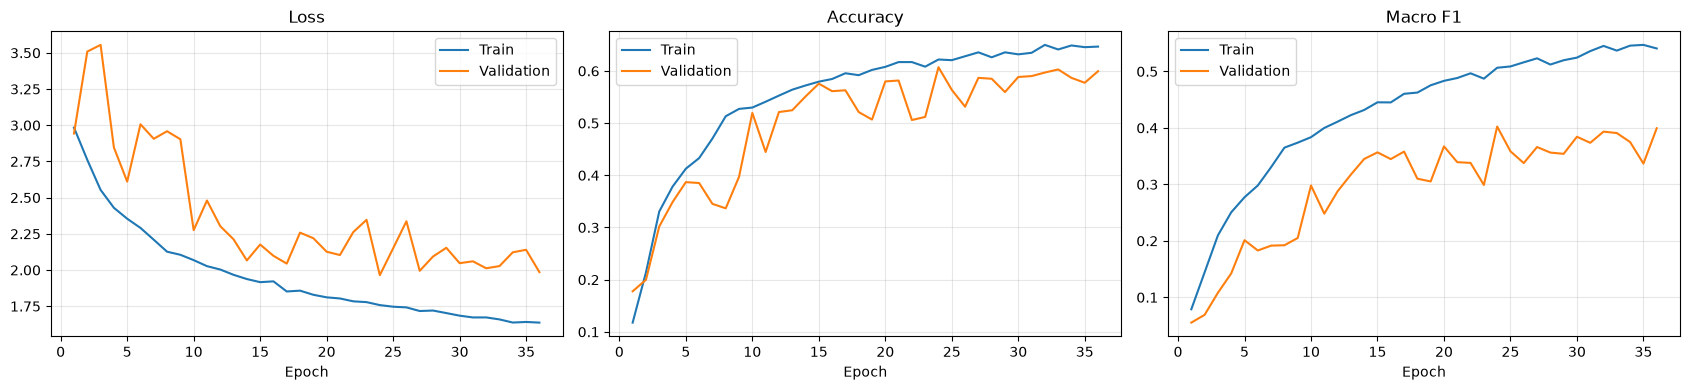

In [20]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 4),
)

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train",
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation",
)

axes[0].set_title("Loss")

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Train",
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation",
)

axes[1].set_title("Accuracy")

axes[2].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train",
)

axes[2].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation",
)

axes[2].set_title("Macro F1")

for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "training_curves.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [21]:
@torch.no_grad()
def predict_dataset(
    model,
    loader,
):
    model.eval()

    y_true = []
    y_pred = []
    probabilities = []
    attention_values = []

    for features, labels in tqdm(
        loader,
        desc="Test",
    ):
        features = features.to(
            DEVICE,
            non_blocking=True,
        )

        logits, attention = model(
            features,
            return_attention=True,
        )

        probability = (
            logits
            .softmax(dim=1)
            .cpu()
        )

        y_true.extend(
            labels.tolist()
        )

        y_pred.extend(
            probability
            .argmax(dim=1)
            .tolist()
        )

        probabilities.append(
            probability
        )

        attention_values.append(
            attention.cpu()
        )

    return (
        np.asarray(y_true),
        np.asarray(y_pred),
        torch.cat(
            probabilities
        ).numpy(),
        torch.cat(
            attention_values
        ).numpy(),
    )


(
    y_true,
    y_pred,
    y_probability,
    person_attention,
) = predict_dataset(
    model,
    test_loader,
)

test_accuracy = accuracy_score(
    y_true,
    y_pred,
)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

print(
    f"Test accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Test Macro F1: "
    f"{test_macro_f1:.4f}"
)

Test: 100%|██████████| 19/19 [00:00<00:00, 19.99it/s]

Test accuracy: 0.6017
Test Macro F1: 0.3882


In [22]:
report_text = classification_report(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
    target_names=class_names,
    zero_division=0,
)

print(report_text)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
    target_names=class_names,
    zero_division=0,
    output_dict=True,
)

with open(
    OUTPUT_ROOT
    / "classification_report.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        report_dict,
        file,
        indent=2,
        ensure_ascii=False,
    )

                          precision    recall  f1-score   support

          00_Short Serve       0.74      1.00      0.85       132
   01_Cross Court Flight       0.11      0.06      0.08        35
                 02_Lift       0.64      0.44      0.52       127
            03_Tap Smash       0.11      0.10      0.10        21
                04_Block       0.41      0.41      0.41        59
            05_Drop Shot       0.44      0.60      0.51       122
            06_Push Shot       0.43      0.51      0.47        51
   07_Transitional Slice       0.30      0.17      0.21        18
                  08_Cut       0.58      0.58      0.58       101
            09_Rush Shot       0.00      0.00      0.00         6
      10_Defensive Clear       0.10      0.22      0.14         9
      11_Defensive Drive       0.00      0.00      0.00         0
                12_Clear       0.84      0.67      0.75       143
           13_Long Serve       0.80      0.85      0.82       150
         

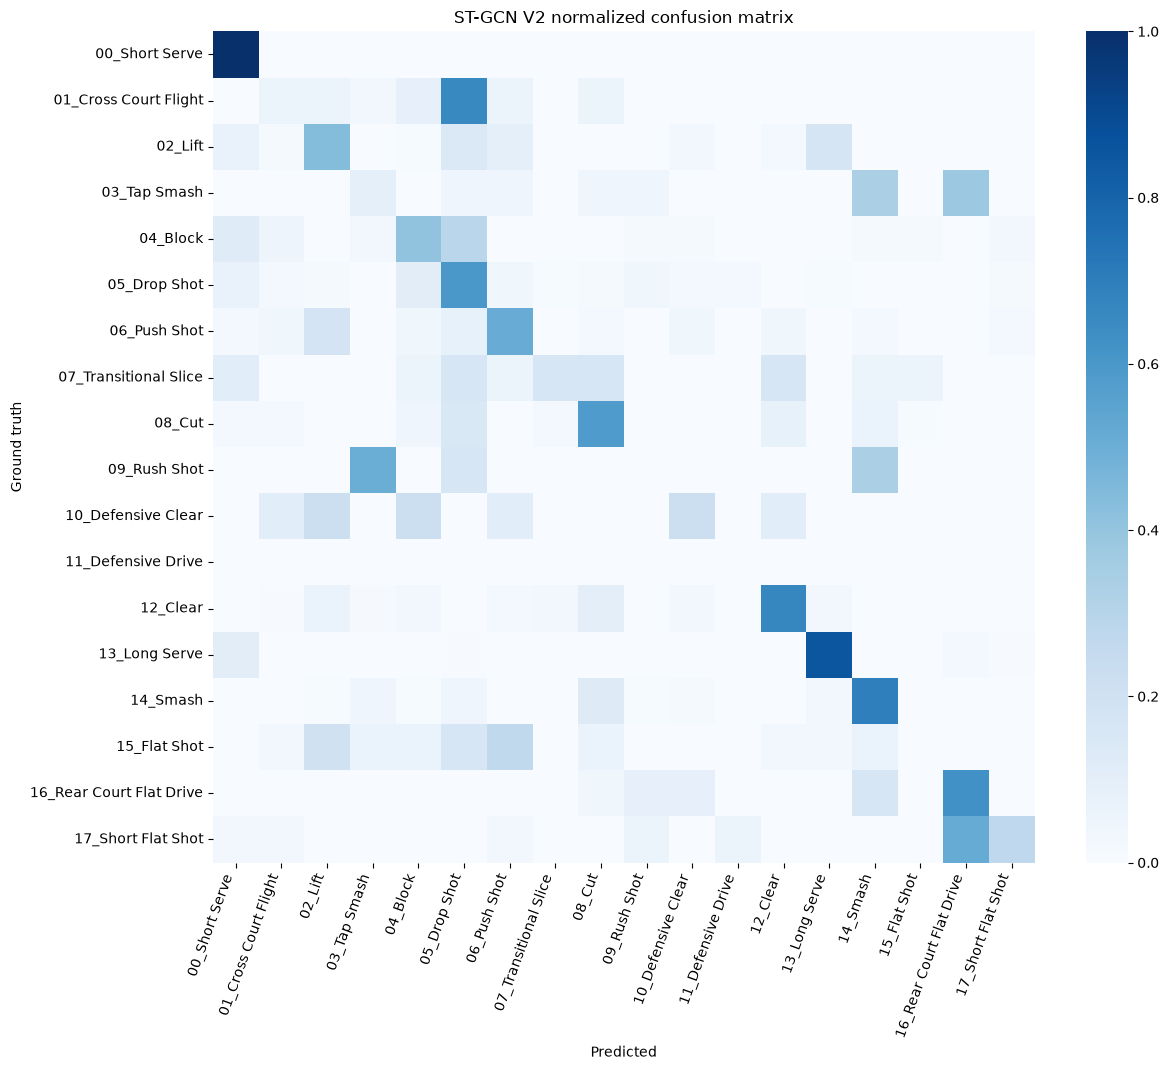

In [23]:
matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
    normalize="true",
)

plt.figure(
    figsize=(
        max(
            11,
            len(class_names) * 0.7,
        ),
        max(
            9,
            len(class_names) * 0.6,
        ),
    )
)

sns.heatmap(
    matrix,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1,
)

plt.xlabel("Predicted")
plt.ylabel("Ground truth")
plt.title(
    "ST-GCN V2 normalized confusion matrix"
)

plt.xticks(
    rotation=70,
    ha="right",
)

plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [24]:
prediction_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

prediction_df["true_label"] = [
    class_names[index]
    for index in y_true
]

prediction_df["predicted_label"] = [
    class_names[index]
    for index in y_pred
]

prediction_df["confidence"] = (
    y_probability.max(axis=1)
)

prediction_df["correct"] = (
    y_true == y_pred
)

prediction_df["person_0_attention"] = (
    person_attention[:, 0]
)

prediction_df["person_1_attention"] = (
    person_attention[:, 1]
)

prediction_df.to_csv(
    OUTPUT_ROOT
    / "test_predictions.csv",
    index=False,
)

print("Dự đoán sai có confidence cao:")

display(
    prediction_df[
        ~prediction_df["correct"]
    ]
    .sort_values(
        "confidence",
        ascending=False,
    )
    .head(20)
)

Dự đoán sai có confidence cao:


,split,label_name,joint_path,score_path,true_label,predicted_label,confidence,correct,person_0_attention,person_1_attention
307,test,03_Tap Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,03_Tap Smash,16_Rear Court Flat Drive,0.997836,False,0.932558,0.067442
308,test,03_Tap Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,03_Tap Smash,16_Rear Court Flat Drive,0.996012,False,0.919826,0.080174
312,test,03_Tap Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,03_Tap Smash,16_Rear Court Flat Drive,0.994318,False,0.902324,0.097676
310,test,03_Tap Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,03_Tap Smash,16_Rear Court Flat Drive,0.993505,False,0.787189,0.212811
306,test,03_Tap Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,03_Tap Smash,16_Rear Court Flat Drive,0.992216,False,0.920137,0.079863
954,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,,13_Long Serve,16_Rear Court Flat Drive,0.986360,False,0.011615,0.988385
309,test,03_Tap Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,03_Tap Smash,16_Rear Court Flat Drive,0.985792,False,0.891804,0.108196
1083,test,14_Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,14_Smash,13_Long Serve,0.978234,False,0.185011,0.814989
493,test,05_Drop Shot,/home/dutai/khacbinh/badminton-stroke/processe...,,05_Drop Shot,00_Short Serve,0.958349,False,0.074970,0.925030
1088,test,14_Smash,/home/dutai/khacbinh/badminton-stroke/processe...,,14_Smash,13_Long Serve,0.956439,False,0.137932,0.862068


,class_id,class_name,correct,total,accuracy
11,11,11_Defensive Drive,0,0,0.000000
15,15,15_Flat Shot,0,30,0.000000
9,9,09_Rush Shot,0,6,0.000000
1,1,01_Cross Court Flight,2,35,0.057143
3,3,03_Tap Smash,2,21,0.095238
7,7,07_Transitional Slice,3,18,0.166667
10,10,10_Defensive Clear,2,9,0.222222
17,17,17_Short Flat Shot,9,33,0.272727
4,4,04_Block,24,59,0.406780
2,2,02_Lift,56,127,0.440945


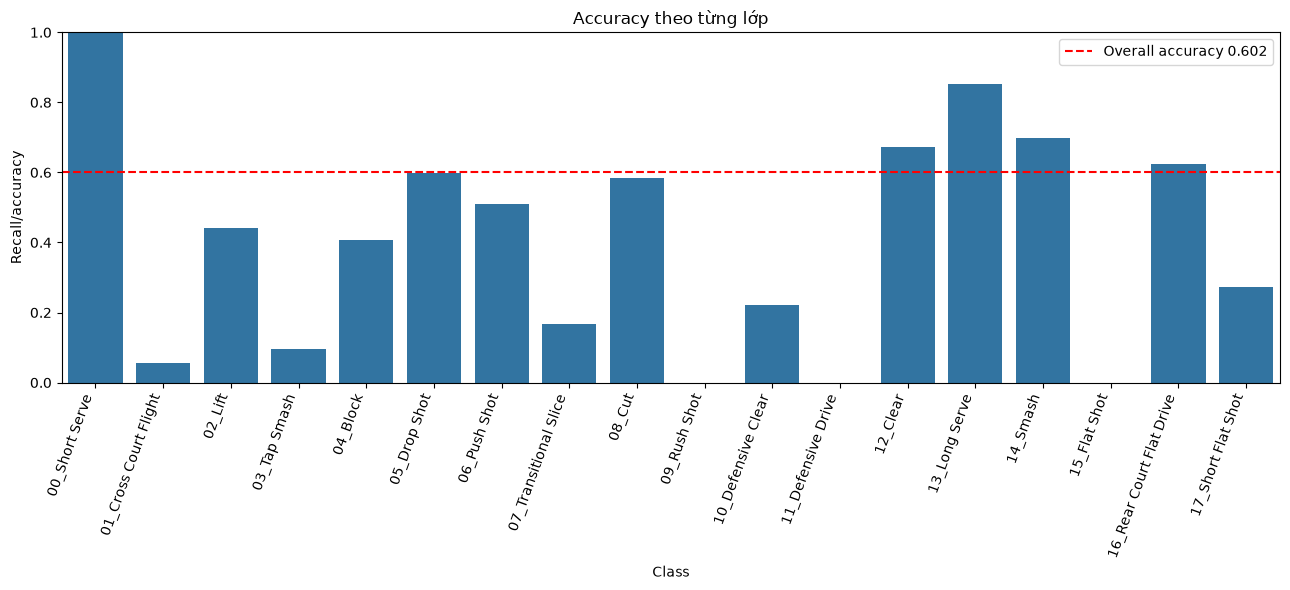

In [25]:
per_class_records = []

for class_id, class_name in enumerate(
    class_names
):
    indices = y_true == class_id
    total = int(indices.sum())

    correct = int(
        (
            y_pred[indices]
            == class_id
        ).sum()
    )

    accuracy = (
        correct / total
        if total > 0
        else 0.0
    )

    per_class_records.append(
        {
            "class_id": class_id,
            "class_name": class_name,
            "correct": correct,
            "total": total,
            "accuracy": accuracy,
        }
    )

per_class_df = pd.DataFrame(
    per_class_records
)

display(
    per_class_df.sort_values(
        "accuracy"
    )
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=per_class_df,
    x="class_name",
    y="accuracy",
)

plt.axhline(
    test_accuracy,
    color="red",
    linestyle="--",
    label=(
        f"Overall accuracy "
        f"{test_accuracy:.3f}"
    ),
)

plt.xticks(
    rotation=70,
    ha="right",
)

plt.ylim(0, 1)
plt.xlabel("Class")
plt.ylabel("Recall/accuracy")
plt.title("Accuracy theo từng lớp")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
confusion_counts = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
)

confusion_records = []

for true_id in range(
    len(class_names)
):
    for predicted_id in range(
        len(class_names)
    ):
        if true_id == predicted_id:
            continue

        count = int(
            confusion_counts[
                true_id,
                predicted_id,
            ]
        )

        if count > 0:
            confusion_records.append(
                {
                    "true_label": (
                        class_names[true_id]
                    ),
                    "predicted_label": (
                        class_names[predicted_id]
                    ),
                    "count": count,
                }
            )

confusion_pairs_df = pd.DataFrame(
    confusion_records
).sort_values(
    "count",
    ascending=False,
)

display(
    confusion_pairs_df.head(30)
)

,true_label,predicted_label,count
3,01_Cross Court Flight,05_Drop Shot,23
13,02_Lift,13_Long Serve,22
9,02_Lift,05_Drop Shot,18
23,04_Block,05_Drop Shot,17
115,17_Short Flat Shot,16_Rear Court Flat Drive,17
84,13_Long Serve,00_Short Serve,16
81,12_Clear,08_Cut,15
62,08_Cut,05_Drop Shot,15
92,14_Smash,08_Cut,15
32,05_Drop Shot,04_Block,13


In [27]:
metadata = {
    "model": "ST-GCN V2",
    "input_channels": [
        "normalized_x",
        "normalized_y",
        "confidence",
        "motion_x",
        "motion_y",
    ],
    "target_frames": TARGET_FRAMES,
    "num_joints": 17,
    "num_persons": 2,
    "num_classes": len(class_names),
    "class_names": class_names,
    "best_epoch": int(
        checkpoint["best_epoch"]
    ),
    "best_val_macro_f1": float(
        checkpoint[
            "best_val_macro_f1"
        ]
    ),
    "test_accuracy": float(
        test_accuracy
    ),
    "test_macro_f1": float(
        test_macro_f1
    ),
    "seed": SEED,
}

with open(
    OUTPUT_ROOT
    / "experiment_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
        ensure_ascii=False,
    )

print(
    "Đã lưu kết quả tại:",
    OUTPUT_ROOT,
)

Đã lưu kết quả tại: /home/dutai/khacbinh/badminton-stroke/processed/stgcn_v2


In [ ]:
summary = {
    "experiment": EXPERIMENT_NAME,
    "input_channels": INPUT_CHANNELS,
    "num_persons": NUM_PERSONS,
    "best_epoch": int(best_epoch),
    "best_val_macro_f1": float(
        best_val_f1
    ),
    "test_accuracy": float(
        test_accuracy
    ),
    "test_macro_f1": float(
        test_macro_f1
    ),
    "test_weighted_f1": float(
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        )
    ),
}

with open(
    ABLATION_ROOT / "summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary,
        file,
        indent=2,
        ensure_ascii=False,
    )

display(
    pd.DataFrame([summary])
)

In [ ]:
ABLATION_BASE = (
    PROJECT_ROOT
    / "processed"
    / "stgcn_ablation"
)

records = []

for summary_path in sorted(
    ABLATION_BASE.glob(
        "*/summary.json"
    )
):
    with open(
        summary_path,
        encoding="utf-8",
    ) as file:
        records.append(
            json.load(file)
        )

comparison_df = pd.DataFrame(
    records
).sort_values(
    "test_macro_f1",
    ascending=False,
)

display(comparison_df)

comparison_df.to_csv(
    ABLATION_BASE
    / "ablation_comparison.csv",
    index=False,
)